# Classification Models II: Logistic Regression and Classifier Evaluation

**EECE5644 Recitation 7 · Main example: South African Heart Disease**

Last time we predicted a continuous target (`lpsa`) with OLS, Ridge, and Lasso. Today the target is a **class label**, `chd ∈ {0, 1}`. The recitation answers two questions:

1. **How does logistic regression turn features into a probability, and how do we fit it?**
2. **Once we have probabilities, how do we judge the classifier?** Precision / recall / F1 (one threshold), ROC / AUC (all thresholds), and calibration (are the probabilities themselves trustworthy?).


**▶ = animation.** These cells produce a small player with play / pause / step buttons. During discussion, pause on a frame and step through it one frame at a time.

**Source and credit.** The data and the from-scratch logistic regression follow [empathy87's ESL Python notebooks](https://github.com/empathy87/The-Elements-of-Statistical-Learning-Python-Notebooks) ([South African Heart Disease](https://github.com/empathy87/The-Elements-of-Statistical-Learning-Python-Notebooks/blob/master/examples/South%20African%20Heart%20Disease.ipynb)) and Chapter 4 of *The Elements of Statistical Learning* (Hastie, Tibshirani, Friedman). Data: CORIS study, Rossouw et al. (1983). Code and text were rewritten for this recitation.

**Run from top to bottom.** Put `South_African_Heart_Disease.csv` in the same folder as this notebook. Dependencies: `pip install numpy pandas scipy matplotlib scikit-learn jupyterlab`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
from scipy.special import expit, logit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score, log_loss, brier_score_loss)
from sklearn.calibration import calibration_curve

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18, 'animation.embed_limit': 60})
BLUE, ORANGE, GREEN, GRAY = '#2768a6', '#d66b2b', '#278267', '#8a8a8a'
SEED = 42

def play(fig, update, frames, interval=250):
    # Turn an update(frame) function into an HTML player with play / step buttons.
    fig.set_dpi(80)
    anim = animation.FuncAnimation(fig, update, frames=frames, interval=interval)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode='once'))

## 1 The data and the three splits

Each row is one male subject. `chd = 1` means coronary heart disease (a **case**), `chd = 0` a control. There are 462 subjects: 160 positive, 302 negative. We use seven predictors:

| Column | Meaning |
|---|---|
| `sbp` | Systolic blood pressure |
| `tobacco` | Cumulative tobacco use (kg) |
| `ldl` | LDL cholesterol |
| `famhist` | Family history of heart disease (Present = 1, Absent = 0) |
| `obesity` | Obesity measurement |
| `alcohol` | Alcohol consumption |
| `age` | Age in years |

**Caveat.** Cases were deliberately over-sampled (35% positive here, much higher than in the general population). Keep this in mind in Section 5: probabilities learned from this sample describe *this sample*.

In [2]:
df = pd.read_csv('South_African_Heart_Disease.csv')
FEATURES = ['sbp', 'tobacco', 'ldl', 'famhist', 'obesity', 'alcohol', 'age']
df['famhist'] = df['famhist'].map({'Absent': 0, 'Present': 1})
X = df[FEATURES].astype(float)
y = df['chd'].astype(int)
print('Rows:', len(df), '| negatives:', (y == 0).sum(), '| positives:', y.sum())
display(df[FEATURES + ['chd']].head())

Rows: 462 | negatives: 302 | positives: 160


,sbp,tobacco,ldl,famhist,obesity,alcohol,age,chd
0,160,12.00,5.73,1,25.30,97.20,52,1
1,144,0.01,4.41,0,28.87,2.06,63,1
2,118,0.08,3.48,1,29.14,3.81,46,0
3,170,7.50,6.41,1,31.99,24.26,58,1
4,134,13.60,3.50,1,25.99,57.34,49,1


**Why three splits?** Each split has one job, and a split used to *make* a choice cannot also give an honest *estimate* of that choice.

| Split | Size | Job |
|---|---:|---|
| Training (60%) | 276 | Fit the scaler and the coefficients |
| Validation (20%) | 93 | Choose the classification threshold; draw ROC / calibration diagnostics |
| Test (20%) | 93 | One final evaluation after every choice is frozen |

`stratify=y` keeps roughly 35% positives in each split.

,Split,n,Positives,Positive fraction
0,Train,276,96,0.348
1,Validation,93,32,0.344
2,Test,93,32,0.344


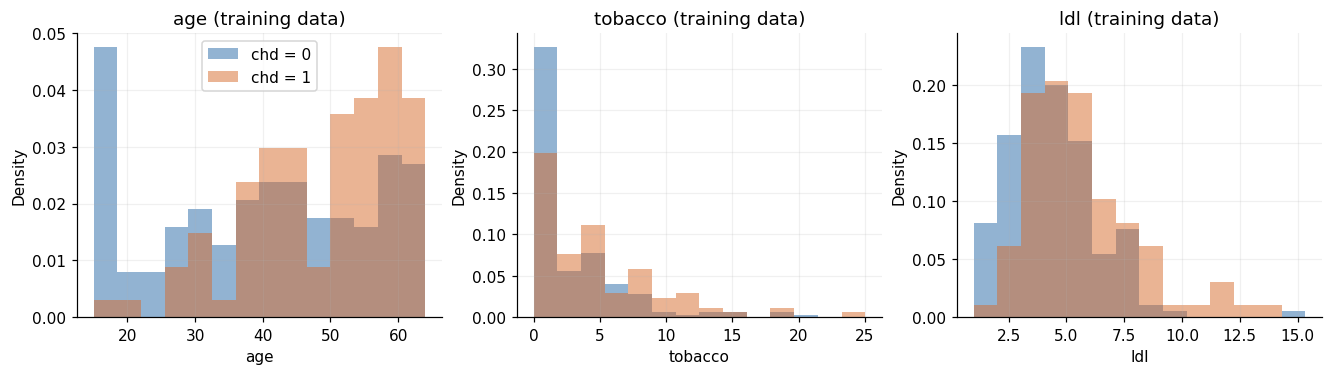

In [3]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
display(pd.DataFrame([[name, len(yy), int(yy.sum()), round(yy.mean(), 3)]
                      for name, yy in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]],
                     columns=['Split', 'n', 'Positives', 'Positive fraction']))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), constrained_layout=True)
for ax, feature in zip(axes, ['age', 'tobacco', 'ldl']):
    edges = np.histogram_bin_edges(X_train[feature], bins=14)
    for cls, color in [(0, BLUE), (1, ORANGE)]:
        ax.hist(X_train.loc[y_train == cls, feature], bins=edges, density=True,
                alpha=0.5, color=color, label=f'chd = {cls}')
    ax.set(xlabel=feature, ylabel='Density', title=f'{feature} (training data)')
axes[0].legend()
plt.show()

**Reading the figure.** Older subjects and heavier smokers are more often positive, but the two classes **overlap**. No single cut-off separates them. So instead of a hard yes/no rule, we want a model that outputs a **probability** $P(\text{chd}=1\mid x)$, and we decide later how to turn that probability into a label.

## 2 From a linear score to a probability

**How is this different from Naive Bayes?** Naive Bayes models what the features typically look like in each class, $P(x\mid y)$ (assuming the features are independent of each other once you know the class), then uses Bayes' rule to flip that into $P(y\mid x)$. Logistic regression skips that step and fits $P(y\mid x)$ directly, with no assumption about how $x$ is distributed. In fact, Gaussian Naive Bayes with a shared covariance across classes produces exactly the sigmoid form derived below — just fit a different way. One practical consequence: when the independence assumption is violated, Naive Bayes's predicted probabilities tend to be overconfident (poorly calibrated), while logistic regression (fit by minimizing cross-entropy) is usually better calibrated; we come back to calibration in Section 5.

### Step 1: a linear score (same as linear regression)

$$z(x)=\beta_0+\beta_1x_1+\dots+\beta_dx_d=\beta_0+x^T\beta .$$

$z$ can be any real number, from $-\infty$ to $+\infty$. A probability must lie in $(0,1)$, so we cannot use $z$ directly.

### Step 2: squash it with the sigmoid

$$p(x)=P(Y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}.$$

| $z$ | $-\infty$ | $-2$ | $0$ | $2$ | $+\infty$ |
|---|---|---|---|---|---|
| $\sigma(z)$ | $0$ | $0.12$ | $0.5$ | $0.88$ | $1$ |

Large positive score → probability near 1; large negative score → near 0; $z=0$ → exactly 0.5.

### What do $\beta_0$ and $\beta_1$ do? (▶ animation)

Below we use **one feature, age** (standardized inside $z$), so that $z=\beta_0+\beta_1\cdot\frac{\text{age}-\bar{\text{age}}}{s}$. Watch three phases:

1. **Slope $\beta_1$ grows** with $\beta_0=0$: the straight line $z$ gets steeper (left), and the S-curve gets **sharper** (right). $\beta_1=0$ is a flat 0.5: age is ignored.
2. **Intercept $\beta_0$ changes** with $\beta_1=1$: the line moves up and down, so the S-curve **slides left/right**. The dashed line marks where $p=0.5$, i.e. $z=0$.
3. **The best fit** (maximum likelihood, Section 3) is shown last.

The **log loss** in the title measures how well each curve fits the data points (smaller is better); we define it in Section 3. Notice that some curves are clearly better than others: fitting = finding the $(\beta_0,\beta_1)$ with the smallest loss.

In [4]:
age = X_train['age'].to_numpy()
age_mu, age_sd = age.mean(), age.std()
age_std = (age - age_mu) / age_sd
yt = y_train.to_numpy(dtype=float)
jitter = np.random.default_rng(0).uniform(-0.04, 0.04, len(age))

# A huge C means essentially no penalty, i.e. plain maximum likelihood.
age_mle = LogisticRegression(C=1e10, tol=1e-10).fit(age_std[:, None], yt)
b0_mle, b1_mle = age_mle.intercept_[0], age_mle.coef_[0, 0]

def mean_log_loss(z, target):
    # Numerically stable form of the binary cross-entropy (Section 3).
    return np.mean(np.logaddexp(0.0, z) - target * z)

frames = ([(0.0, s, 'Phase 1: change slope') for s in np.linspace(0, 3, 13)]
          + [(b, 1.0, 'Phase 2: change intercept') for b in np.linspace(-2, 2, 13)]
          + [(b0_mle, b1_mle, 'Phase 3: maximum-likelihood fit')] * 4)
age_grid = np.linspace(age.min() - 3, age.max() + 3, 300)
fig, (ax_z, ax_p) = plt.subplots(1, 2, figsize=(11.5, 3.9), constrained_layout=True)

def update(frame):
    b0, b1, phase = frame
    z_grid = b0 + b1 * (age_grid - age_mu) / age_sd
    loss = mean_log_loss(b0 + b1 * age_std, yt)
    for ax in (ax_z, ax_p):
        ax.clear()
    ax_z.plot(age_grid, z_grid, color=GREEN, lw=2)
    ax_z.axhline(0, color=GRAY, lw=0.8)
    ax_z.set(xlabel='Age (years)', ylabel='Linear score z (log-odds)', ylim=(-7, 7),
             title=f'z = {b0:+.2f} {b1:+.2f} · standardized age')
    ax_p.scatter(age, yt + jitter, c=np.where(yt == 1, ORANGE, BLUE), s=14, alpha=0.45)
    ax_p.plot(age_grid, expit(z_grid), color=GREEN, lw=2.5)
    if abs(b1) > 1e-9:
        age_half = age_mu - b0 / b1 * age_sd
        if age_grid[0] < age_half < age_grid[-1]:
            ax_p.axvline(age_half, color='black', ls='--', lw=1)
            ax_p.text(age_half + 0.8, 0.53, f'p = 0.5 at age {age_half:.0f}', fontsize=9)
    ax_p.axhline(0.5, color=GRAY, lw=0.8, ls=':')
    ax_p.set(xlabel='Age (years)', ylabel='p = sigmoid(z) / observed label',
             ylim=(-0.08, 1.08), title=f'{phase}   |   log loss = {loss:.3f}')

play(fig, update, frames, interval=350)

### What is "linear" about logistic regression?

Invert the sigmoid. With **odds** $=\dfrac{p}{1-p}$ ("how many positives per negative"):

$$\frac{p(x)}{1-p(x)}=e^{z(x)}\qquad\Longrightarrow\qquad \underbrace{\log\frac{p(x)}{1-p(x)}}_{\text{log-odds (logit)}}=\beta_0+x^T\beta .$$

The **log-odds are linear** in the features (left panel of the animation); the probability is not (right panel).

| $p$ | 0.2 | 0.5 | 0.8 |
|---|---|---|---|
| odds $p/(1-p)$ | 0.25 (1 positive : 4 negatives) | 1 | 4 (4 : 1) |
| log-odds | $-1.39$ | $0$ | $+1.39$ |

**Interpreting a coefficient.** Increase feature $x_j$ by one unit, holding the others fixed:
- the log-odds increase by $\beta_j$;
- the odds are **multiplied** by $e^{\beta_j}$ (the *odds ratio*);
- the probability does **not** increase by $\beta_j$. Example: $\beta_j=\log 2$ doubles the odds. Starting at $p=0.2$ (odds 0.25), the new odds are 0.5, so $p=0.5/1.5=0.33$, not $0.4$.

**Why not just fit OLS to the 0/1 labels?** Its straight-line predictions leave $[0,1]$ for extreme inputs (the left panel would be read as a "probability" of $-3$ or $+5$), and its squared-error loss does not match a yes/no outcome. Logistic regression models the label as a coin flip whose probability is $\sigma(z)$; that is the next section.

## 3 Where does the loss come from? Bernoulli likelihood → cross-entropy

Linear regression: Gaussian noise + maximum likelihood ⇒ least squares. Same recipe here, but the label is a **coin flip** with probability $p_i=\sigma(z_i)$:

$$P(Y_i=y_i\mid x_i)=p_i^{\,y_i}(1-p_i)^{1-y_i}=\begin{cases}p_i & \text{if } y_i=1\\ 1-p_i & \text{if } y_i=0\end{cases}$$

The formula is just a compact way of saying "the probability the model gave to what actually happened."

Assume subjects are independent, so the joint probability of the whole training set is the **product** of the per-subject probabilities above. Say three subjects have labels $y_1=1, y_2=0, y_3=1$ and the model gives $p_1=0.8$, $p_2=0.7$, $p_3=0.9$; plugging into the formula above, the joint probability is $p_1\times(1-p_2)\times p_3=0.8\times0.3\times0.9=0.216$. With only three subjects this is already a small number, and with hundreds of subjects the product of hundreds of numbers below 1 underflows toward $0$ — a computer cannot represent a number like $10^{-80}$.

So we take $\log$ first. $\log(A\times B\times C)=\log A+\log B+\log C$ turns a product into a sum, which stays numerically well-behaved no matter how many subjects there are. Combined with $\log(a^b)=b\log a$, this turns $p_i^{y_i}(1-p_i)^{1-y_i}$ into $y_i\log p_i+(1-y_i)\log(1-p_i)$ — the same two cases as the piecewise formula above, just added instead of multiplied. Flip the sign so that we **minimize** instead of maximize, and divide by $n$ to get an average. This is the **binary cross-entropy**, or **log loss**:

$$L(\beta_0,\beta)=-\frac1n\sum_{i=1}^n\Big[y_i\log p_i+(1-y_i)\log(1-p_i)\Big].$$

Per subject, only one term is active:
- true positive label ($y_i=1$): loss $=-\log p_i$,
- true negative label ($y_i=0$): loss $=-\log(1-p_i)$.

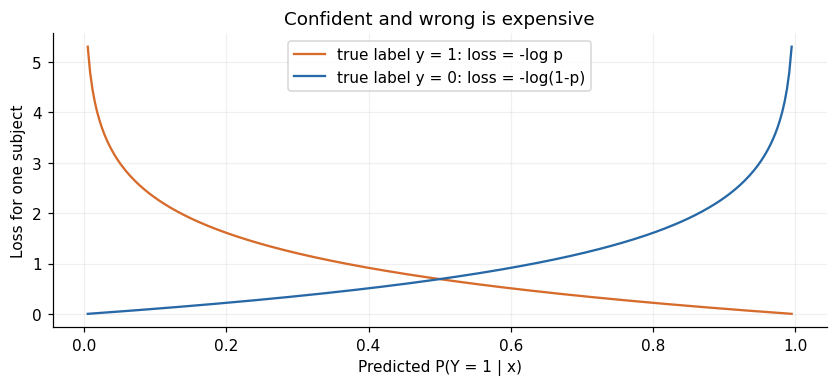

,Predicted p for a positive subject,Loss = -log p
0,0.99,0.010
1,0.90,0.105
2,0.50,0.693
3,0.10,2.303
4,0.01,4.605


In [5]:
p_grid = np.linspace(0.005, 0.995, 300)
fig, ax = plt.subplots(figsize=(7.5, 3.4), constrained_layout=True)
ax.plot(p_grid, -np.log(p_grid), color=ORANGE, label='true label y = 1: loss = -log p')
ax.plot(p_grid, -np.log1p(-p_grid), color=BLUE, label='true label y = 0: loss = -log(1-p)')
ax.set(xlabel='Predicted P(Y = 1 | x)', ylabel='Loss for one subject',
       title='Confident and wrong is expensive')
ax.legend()
plt.show()
display(pd.DataFrame({'Predicted p for a positive subject': [0.99, 0.9, 0.5, 0.1, 0.01],
                      'Loss = -log p': -np.log([0.99, 0.9, 0.5, 0.1, 0.01])}).round(3))

**Read the table.** Saying 0.9 for a positive costs 0.105; saying 0.5 ("no idea") costs 0.69; saying 0.01 costs 4.6. Being **confidently wrong** is punished far more than being unsure. This is why log loss rewards *honest* probabilities, a theme we return to in calibration.

### The gradient is "prediction minus truth"

$L_i$ depends on $z_i$ only through $p_i=\sigma(z_i)$, so by the **chain rule**:

$$\frac{\partial L_i}{\partial z_i}=\frac{\partial L_i}{\partial p_i}\cdot\frac{\partial p_i}{\partial z_i}.$$

Each factor is easy on its own. Differentiating $L_i=-\big[y_i\log p_i+(1-y_i)\log(1-p_i)\big]$ with respect to $p_i$ (using $\frac{d}{dx}\log x=1/x$):

$$\frac{\partial L_i}{\partial p_i}=-\frac{y_i}{p_i}+\frac{1-y_i}{1-p_i}.$$

And the sigmoid has the convenient property $\sigma'(z)=\sigma(z)\big(1-\sigma(z)\big)$, so:

$$\frac{\partial p_i}{\partial z_i}=p_i(1-p_i).$$

Multiplying the two and distributing $p_i(1-p_i)$ into each term **cancels both denominators**:

$$\frac{\partial L_i}{\partial z_i}=\Big[-\frac{y_i}{p_i}+\frac{1-y_i}{1-p_i}\Big]\,p_i(1-p_i)=-y_i(1-p_i)+(1-y_i)p_i=-y_i+\underbrace{y_ip_i}_{}+p_i-\underbrace{y_ip_i}_{}.$$

The two $y_ip_i$ terms are equal and opposite, so they cancel, leaving the clean result

$$\frac{\partial L_i}{\partial z_i}=p_i-y_i,\qquad
\nabla_b L=\frac1n A^T(p-y),$$

where $A=[\mathbf 1, Z]$ is the design matrix (intercept column + standardized features) and $b=(\beta_0,\beta_1,\dots,\beta_d)$.

- $p_i-y_i>0$ (predicted too high for this subject) → gradient descent **lowers** its score.
- $p_i-y_i<0$ (predicted too low) → it **raises** its score.

## 4 Fit logistic regression with gradient descent

Gradient descent repeats

$$b \leftarrow b-\eta\,\nabla_b L = b-\eta\,\frac1n A^T\big(\sigma(Ab)-y\big).$$

Instead of guessing the step size $\eta$, we use the safe choice $\eta = 1/\big(\|A\|_2^2/(4n)\big)$ (the inverse of an upper bound on the curvature). Each line of `objective_and_gradient` matches one formula:

| Code | Formula |
|---|---|
| `z = A @ b` | scores $z_i$ |
| `np.logaddexp(0, z) - y * z` | per-subject log loss, $\log(1+e^{z_i})-y_iz_i$ (same value, no overflow) |
| `expit(z) - y` | residuals $p_i-y_i$ |
| `A.T @ (...) / n` | gradient $\frac1nA^T(p-y)$ |

In [6]:
def objective_and_gradient(b, A, target):
    z = A @ b
    loss = np.mean(np.logaddexp(0.0, z) - target * z)
    gradient = A.T @ (expit(z) - target) / len(target)
    return loss, gradient

def fit_logistic_gd(A, target, step=None, tol=1e-8, max_iter=50000):
    b = np.zeros(A.shape[1])
    if step is None:                            # safe default: 1 / curvature bound
        step = 1.0 / (np.linalg.norm(A, ord=2)**2 / (4 * len(target)))
    path = []                                   # (b, loss) at every iteration
    for _ in range(max_iter):
        loss, gradient = objective_and_gradient(b, A, target)
        path.append((b.copy(), loss))
        if np.max(np.abs(gradient)) < tol:
            return b, path
        b = b - step * gradient
    raise RuntimeError('GD did not converge.')

### ▶ Watch gradient descent learn a decision boundary

To *see* the fit, we temporarily use **two features, age and tobacco**. Each frame is one gradient-descent iteration (spaced logarithmically, since most of the change happens early):

- **Left:** the shading is the model's $P(\text{chd}=1)$; the black line is the **decision boundary** $p=0.5$, i.e. $z=0$. Because $z$ is linear in the features, the boundary is a **straight line**.
- **Right:** the training log loss falls and flattens: we approach the minimum.

Iteration 0 is $b=0$: every subject gets $p=0.5$ and the loss is $\log 2\approx0.693$. With the safe step size this 3-parameter problem converges in fewer than 20 iterations, too fast to watch, so the animation uses a deliberately **small step $\eta=0.1$**. The path is the same idea in slow motion.

In [7]:
viz_features = ['age', 'tobacco']
viz_scaler = StandardScaler().fit(X_train[viz_features])
A_viz = np.column_stack([np.ones(len(X_train)), viz_scaler.transform(X_train[viz_features])])
b_viz, viz_path = fit_logistic_gd(A_viz, yt, step=0.1, tol=1e-4)
viz_losses = np.array([loss for _, loss in viz_path])

gx, gy = np.meshgrid(np.linspace(13, 67, 120), np.linspace(-1, 33, 120))
grid_A = np.column_stack([np.ones(gx.size),
                          viz_scaler.transform(pd.DataFrame({'age': gx.ravel(), 'tobacco': gy.ravel()}))])
frame_ids = np.unique(np.r_[0, np.geomspace(1, len(viz_path) - 1, 36).astype(int)])
frame_ids = list(frame_ids) + [frame_ids[-1]] * 3
fig, (ax_b, ax_l) = plt.subplots(1, 2, figsize=(12, 4.1), constrained_layout=True,
                                 gridspec_kw={'width_ratios': [1.35, 1]})

def update(it):
    b, loss = viz_path[it]
    ax_b.clear(); ax_l.clear()
    surface = expit(grid_A @ b).reshape(gx.shape)
    ax_b.contourf(gx, gy, surface, levels=np.linspace(0, 1, 11), cmap='Blues', alpha=0.55, vmin=0, vmax=1)
    if surface.min() < 0.5 < surface.max():
        ax_b.contour(gx, gy, surface, levels=[0.5], colors='black', linewidths=2)
    for cls, color in [(0, BLUE), (1, ORANGE)]:
        m = y_train == cls
        ax_b.scatter(X_train.loc[m, 'age'], X_train.loc[m, 'tobacco'], color=color,
                     edgecolors='white', linewidths=0.4, s=22, label=f'chd = {cls}')
    ax_b.set(xlabel='Age (years)', ylabel='Cumulative tobacco (kg)',
             title=f'Iteration {it}:  b = [{b[0]:+.2f}, {b[1]:+.2f}, {b[2]:+.2f}]')
    ax_b.legend(loc='upper left', fontsize=9)
    ax_l.plot(viz_losses, color=GRAY, lw=1, alpha=0.4)
    ax_l.plot(np.arange(it + 1), viz_losses[:it + 1], color=BLUE, lw=2)
    ax_l.scatter([it], [loss], color=ORANGE, zorder=5, s=40)
    ax_l.set(xlabel='Iteration', ylabel='Training log loss',
             ylim=(viz_losses.min() - 0.02, 0.71), title=f'log loss = {loss:.4f}')

play(fig, update, frame_ids, interval=250)

**What to notice.** In early iterations the intercept is still close to 0, so the line sits too far to the lower left and too many subjects are on the "likely CHD" side. As the intercept becomes more negative, the line moves toward older subjects and heavier smokers and tilts while the two weights settle. Each step reduces the loss. Once the loss curve is flat, the line barely moves. It stays straight throughout, because $z$ is linear in the features.

### The model we evaluate from here on

From now on we use scikit-learn's `LogisticRegression` with its default mild **L2 penalty** (`C=1`; smaller `C` = stronger penalty, the same idea as Ridge last week) inside a `Pipeline`, so the scaler is always fitted on training data only. Sections 5 and 6 are about **evaluation**; the model is frozen.

In [8]:
model = Pipeline([('scale', StandardScaler()), ('lr', LogisticRegression(C=1.0))]).fit(X_train, y_train)
p_val = model.predict_proba(X_val)[:, 1]          # column 1 = P(chd = 1)
y_v = y_val.to_numpy()
print(f'Validation subjects: {len(y_v)} ({y_v.sum()} positive, {(y_v == 0).sum()} negative)')
print('First five validation probabilities:', p_val[:5].round(3))

Validation subjects: 93 (32 positive, 61 negative)
First five validation probabilities: [0.171 0.208 0.255 0.674 0.109]


## 5 Calibration: can we trust the probability values?

### How does this compare to Naive Bayes?

Naive Bayes builds its classifier the other way around from logistic regression. For each class it models what the **features** typically look like, $P(x\mid y)$ — assuming the features are independent of each other once you know the class, so $P(x\mid y)=\prod_j P(x_j\mid y)$ — and then uses Bayes' rule to flip that into $P(y\mid x)$. Logistic regression skips that step and fits $P(y\mid x)=\sigma(\beta_0+x^T\beta)$ directly (Section 2). The two are not as different as they look: if Naive Bayes assumes each feature is Gaussian with the same spread in both classes, its formula for $P(y\mid x)$ reduces algebraically to this exact sigmoid — just fit a different way (Naive Bayes reads its coefficients off class-conditional means and variances; logistic regression fits them by minimizing cross-entropy, Section 3).

The catch is that "independent once you know the class" assumption. Features like `sbp`, `ldl`, and `obesity` are plausibly correlated, and when that happens Naive Bayes effectively counts the same evidence more than once, pushing its predicted probability toward 0 or 1 further than the data actually supports. The ranking of subjects can still come out fine, but the probability **values** are overconfident. Logistic regression, fit by minimizing cross-entropy directly against the labels, has no such built-in bias — which is exactly the kind of thing calibration is designed to catch.

**A concrete example.** Suppose `sbp` and `obesity` are almost two measurements of the same thing in disguise (heavier subjects tend to have higher blood pressure), and conditional on having CHD, seeing *either one* on its own would shift the odds of disease by a factor of 3 (a likelihood ratio of 3). If the two features were genuinely independent evidence, seeing *both* should multiply the odds by $3\times3=9$. But since they are really two readings of one underlying fact, the honest effect of seeing both is closer to the effect of seeing one, say $\times3$, not $\times9$. Naive Bayes does not know they are correlated, so it multiplies both factors in anyway: starting from even 1:1 prior odds, it lands on 9:1 odds ($p\approx0.90$), while the data really only supports something closer to 3:1 odds ($p\approx0.75$). This subject is probably still ranked above someone with neither risk factor — the ranking survives — but the reported probability, 0.90, overstates the honest risk of 0.75. That gap between "ranked correctly" and "the number is right" is exactly what calibration checks.

**Seeing it on correlated features.** The cell below makes this concrete. `x1` and `x2` are two noisy copies of the same underlying signal (like `sbp` and `obesity` both tracking body weight) — correlated with each other, and each one informative about the label on its own. We fit a Gaussian Naive Bayes classifier and a logistic regression on the same data and compare their reliability diagrams.

Correlation between x1 and x2: 0.91


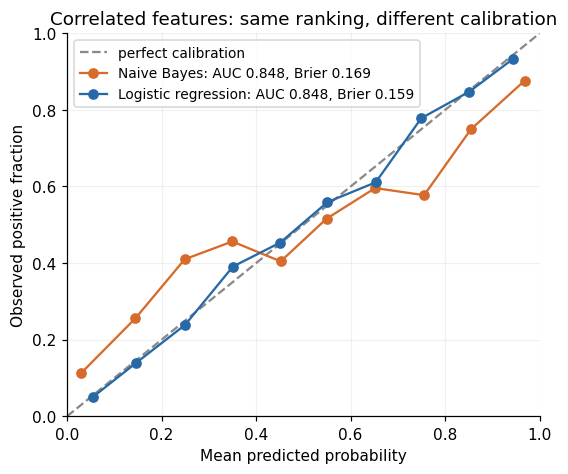

In [9]:
from sklearn.naive_bayes import GaussianNB

rng_nb = np.random.default_rng(0)
n_demo = 4000
y_demo = rng_nb.binomial(1, 0.5, n_demo)
signal = rng_nb.normal(0, 1, n_demo) + 1.5 * y_demo       # shared underlying signal
x1 = signal + rng_nb.normal(0, 0.4, n_demo)                # two noisy, correlated
x2 = signal + rng_nb.normal(0, 0.4, n_demo)                # readings of that signal
X_demo = np.column_stack([x1, x2])
print(f'Correlation between x1 and x2: {np.corrcoef(x1, x2)[0, 1]:.2f}')

p_nb = GaussianNB().fit(X_demo, y_demo).predict_proba(X_demo)[:, 1]
p_lr_demo = LogisticRegression().fit(X_demo, y_demo).predict_proba(X_demo)[:, 1]

fig, ax = plt.subplots(figsize=(5, 4.2), constrained_layout=True)
ax.plot([0, 1], [0, 1], ls='--', color=GRAY, label='perfect calibration')
for p, name, color in [(p_nb, 'Naive Bayes', ORANGE), (p_lr_demo, 'Logistic regression', BLUE)]:
    obs, pred = calibration_curve(y_demo, p, n_bins=10)
    ax.plot(pred, obs, marker='o', color=color,
            label=f'{name}: AUC {roc_auc_score(y_demo, p):.3f}, Brier {brier_score_loss(y_demo, p):.3f}')
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted probability',
       ylabel='Observed positive fraction', title='Correlated features: same ranking, different calibration')
ax.legend(fontsize=9, loc='upper left')
plt.show()

**What to notice.** The two AUCs come out almost identical — both models rank subjects the same way, because `x1` and `x2` still carry real information about `y` even though they overlap. The reliability diagram tells a different story: Naive Bayes's curve sags well below the diagonal on the right (its high predicted probabilities are too high — overconfident), while logistic regression's curve tracks the diagonal much more closely. This is the correlated-feature effect from the worked example above, made visible: double-counted evidence inflates Naive Bayes's probability values without improving — or even while leaving unchanged — its ranking.

### Order vs. values

AUC asks whether the **order** is right. **Calibration** asks whether the **numbers** are right:

> Among all subjects to whom the model says "$p\approx 0.7$", do about 70% actually have CHD?

This matters whenever the probability itself is used: a doctor telling a patient "your risk is 30%", or choosing a decision threshold based on the relative costs of false positives and false negatives, which assumes calibrated probabilities.

### How a reliability diagram is built

1. Sort the subjects into bins by predicted probability (e.g. 0–0.1, 0.1–0.2, …).
2. In each bin, compute two numbers:
   - **Mean predicted probability** (x): average the model's $p_i$ over everyone in that bin — e.g. a bin of 19 subjects with predictions averaging to 0.75.
   - **Observed positive fraction** (y): among those same subjects, what fraction were *actually* positive ($y_i=1$)? Since each $y_i$ is just 0 or 1, averaging the labels directly gives this fraction — e.g. if 14 of those 19 subjects truly had CHD, the observed fraction is $14/19\approx0.74$.
3. Plot y against x, one point per bin. A perfectly calibrated model lies on the **diagonal** ($y=x$): "the model said 75%" and "75% of them actually were positive" would match exactly.

- Points **below** the diagonal: predicted higher than reality → **over-predicts** risk in that bin.
- Points **above**: **under-predicts**.

### Two summary numbers

- **Brier score** $=\frac1n\sum_i(p_i-y_i)^2$: squared error of the probabilities (0 is perfect; always predicting 0.5 gives 0.25).
- **Log loss** (Section 3): punishes confident mistakes hardest.

Both reward calibration **and** good ranking together, so neither is a pure calibration measure; the diagram shows calibration directly.

### Calibration of our heart-disease model

The real model on the 93 validation subjects, with 5 bins containing equal numbers of subjects. The table lists the bin values, so you can see exactly what each dot is.

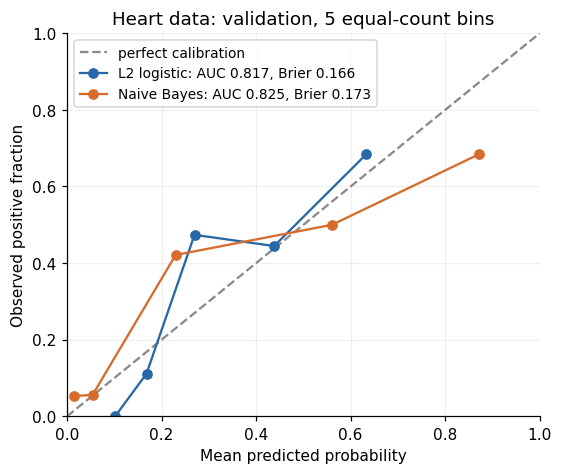

,n,mean_predicted,observed_fraction
bin,,,
0,19,0.102,0.000
1,18,0.168,0.111
2,19,0.269,0.474
3,18,0.438,0.444
4,19,0.633,0.684


,n,mean_predicted,observed_fraction
bin,,,
0,19,0.014,0.053
1,18,0.054,0.056
2,19,0.230,0.421
3,18,0.561,0.500
4,19,0.872,0.684


In [10]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB().fit(X_train, y_train)
p_nb_val = nb_model.predict_proba(X_val)[:, 1]

bins = pd.qcut(p_val, 5, labels=False)
cal_table = pd.DataFrame({'p': p_val, 'y': y_v, 'bin': bins}).groupby('bin').agg(
    n=('y', 'size'), mean_predicted=('p', 'mean'), observed_fraction=('y', 'mean'))
bins_nb = pd.qcut(p_nb_val, 5, labels=False)
cal_table_nb = pd.DataFrame({'p': p_nb_val, 'y': y_v, 'bin': bins_nb}).groupby('bin').agg(
    n=('y', 'size'), mean_predicted=('p', 'mean'), observed_fraction=('y', 'mean'))

fig, ax = plt.subplots(figsize=(5, 4.2), constrained_layout=True)
ax.plot([0, 1], [0, 1], ls='--', color=GRAY, label='perfect calibration')
ax.plot(cal_table.mean_predicted, cal_table.observed_fraction, marker='o', color=BLUE,
        label=f'L2 logistic: AUC {roc_auc_score(y_v, p_val):.3f}, Brier {brier_score_loss(y_v, p_val):.3f}')
ax.plot(cal_table_nb.mean_predicted, cal_table_nb.observed_fraction, marker='o', color=ORANGE,
        label=f'Naive Bayes: AUC {roc_auc_score(y_v, p_nb_val):.3f}, Brier {brier_score_loss(y_v, p_nb_val):.3f}')
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted probability',
       ylabel='Observed positive fraction', title='Heart data: validation, 5 equal-count bins')
ax.legend(fontsize=9, loc='upper left')
plt.show()
display(cal_table.round(3))
display(cal_table_nb.round(3))

**Reading the heart-data plot.** Each bin has only about 19 subjects, so one subject changes the observed fraction by about 0.05. Small wiggles around the diagonal are noise, not evidence of miscalibration. Logistic regression, which directly minimizes log loss, is usually reasonably calibrated **on data like its training data**.

**Naive Bayes on the same data.** The AUCs are close — Naive Bayes ranks subjects about as well as logistic regression here, since `sbp`, `ldl`, and `obesity` are only mildly correlated in this dataset (around 0.2–0.3), not the extreme redundancy of the earlier synthetic example. But look at the highest-risk bin: Naive Bayes's predicted probability there is noticeably higher than the observed fraction, a bigger gap than logistic regression shows in the same bin — a smaller-scale version of the same overconfidence effect, now visible on a real model instead of a synthetic one. Models such as SVMs, boosted trees, or heavily regularized models can show the same kind of miscalibration and often need recalibration.

**Calibrated for which population?** All our splits come from the same case-control sample with 35% cases. A model that is calibrated here will **over-estimate** risk in a general population where CHD is much rarer, even though its ranking (AUC) may transfer. Calibration is always "calibrated **for a specific population**."

## 6 Evaluate once on the untouched test set

Everything is frozen: the seven features and the L2 model with `C=1`. We now look at the test labels **for the first and only time**. We compare an "always negative" baseline (predicts the training positive fraction for everyone) against our model at the default threshold 0.5.

In [11]:
p_test = model.predict_proba(X_test)[:, 1]
y_te = y_test.to_numpy()

def evaluate(name, probabilities, threshold):
    pred = (probabilities >= threshold).astype(int)
    return {'Model / rule': name, 'threshold': threshold,
            'Accuracy': accuracy_score(y_te, pred),
            'Precision': precision_score(y_te, pred, zero_division=0),
            'Recall': recall_score(y_te, pred), 'F1': f1_score(y_te, pred),
            'ROC-AUC': roc_auc_score(y_te, probabilities),
            'AP': average_precision_score(y_te, probabilities),
            'Brier': brier_score_loss(y_te, probabilities),
            'Log loss': log_loss(y_te, probabilities)}

results = pd.DataFrame([
    evaluate('Always negative (train prior)', np.full(len(y_te), y_train.mean()), 0.5),
    evaluate('Logistic, threshold 0.50', p_test, 0.5)])
display(results.round(3))
pred_test = (p_test >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred_test).ravel()
display(pd.DataFrame([[tn, fp], [fn, tp]], index=['True 0', 'True 1'],
                     columns=['Predicted 0', 'Predicted 1']).rename_axis('Test, threshold 0.50'))

,Model / rule,threshold,Accuracy,Precision,Recall,F1,ROC-AUC,AP,Brier,Log loss
0,Always negative (train prior),0.5,0.656,0.000,0.000,0.000,0.500,0.344,0.226,0.644
1,"Logistic, threshold 0.50",0.5,0.753,0.636,0.656,0.646,0.795,0.664,0.175,0.521


,Predicted 0,Predicted 1
"Test, threshold 0.50",,
True 0,49,12
True 1,11,21


## References

- Hastie, Tibshirani, Friedman. *The Elements of Statistical Learning*, 2nd ed., Ch. 4 (logistic regression, South African heart disease example). [Book site](https://hastie.su.domains/ElemStatLearn/).
- Rossouw et al. (1983). Coronary risk factor screening in three rural communities: The CORIS baseline study. *South African Medical Journal* 64, 430–436.
- empathy87, [South African Heart Disease notebook](https://github.com/empathy87/The-Elements-of-Statistical-Learning-Python-Notebooks/blob/master/examples/South%20African%20Heart%20Disease.ipynb) and [source data](https://github.com/empathy87/The-Elements-of-Statistical-Learning-Python-Notebooks/blob/master/data/South%20African%20Heart%20Disease.txt).
- scikit-learn documentation: [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics), [probability calibration](https://scikit-learn.org/stable/modules/calibration.html).